# 00. Tổng quan Dữ liệu (Data Overview)

Mục tiêu: Đánh giá tổng quan toàn bộ 8 bảng dữ liệu Dunnhumby theo chuẩn hợp đồng:
- **Structure**: Kích thước bảng (rows, cols), memory usage, danh sách cột và kiểu dữ liệu
- **Grain**: Kiểm định candidate grain, số nhóm trùng lặp (duplicate groups), excess rows, tính duy nhất (`is_unique`), và tính hợp lệ (`is_valid`)
- **Key**: Phân tích các khóa định danh (cardinality, missingness, uniqueness, validity)
- **Time Coverage**: Đánh giá độ phủ thời gian có ngữ nghĩa (ordinal DAY/WEEK_NO, clock code TRANS_TIME, interval START_DAY/END_DAY)
- **Quality cơ bản**: Tỷ lệ missing, blank string, cột hằng số (constant), và trùng lặp toàn dòng (exact duplicate rows)
- **Numeric Distribution**: Thống kê phân phối các cột định lượng (count, mean, std, min, p25, median, p75, max) tương đương `df.describe()`
- **Categorical Distribution**: Thống kê phân phối các cột phân loại (count, unique, top, freq, missing_rate) tương đương df.describe(include=['O', 'category'])\n

Toàn bộ logic được đóng gói trong package `propensity.overview`. Notebook chỉ gọi orchestrator và hiển thị kết quả.

In [42]:
from math import ceil
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from propensity.overview import build_dunnhumby_overview
from propensity.overview.activity_dashboard import (
    load_transaction_activity_dashboard,
    plot_transaction_activity_dashboard,
)
from propensity.schema.dunnhumby import DUNNHUMBY_CATALOG

In [43]:
raw_dir = Path("../data/raw/Dunnhumby")
report = build_dunnhumby_overview(raw_dir=raw_dir)

## 1. Table Summary (Structure)

In [44]:
report.table_summary

,table,n_rows,n_columns,memory_bytes
0,transaction,2595732,12,259573332
1,product,92353,7,10190962
2,demographic,801,8,87189
3,campaign_desc,30,4,1272
4,campaign_table,7208,3,223580
5,coupon,124548,3,3362928
6,coupon_redempt,2318,4,81262
7,causal,36786524,5,1618607188


## 2. Column Summary

In [45]:
report.column_summary

,table,column,dtype,role,is_required,is_identifier,is_grain,is_time
0,transaction,household_key,Int64,entity,True,True,False,False
1,transaction,BASKET_ID,Int64,id,True,True,True,False
2,transaction,DAY,int64,time,True,False,False,True
3,transaction,PRODUCT_ID,Int64,id,True,True,True,False
4,transaction,QUANTITY,int64,numeric,True,False,False,False
5,transaction,SALES_VALUE,float64,numeric,True,False,False,False
6,transaction,STORE_ID,Int64,id,True,True,False,False
7,transaction,RETAIL_DISC,float64,numeric,False,False,False,False
8,transaction,TRANS_TIME,int64,time,True,False,False,True
9,transaction,WEEK_NO,int64,time,True,False,False,True


### 2.1. Số cột theo semantic type

Mỗi cột của từng bảng được tính một lần. Sáu nhóm loại trừ nhau: khóa định danh; biến thời gian; biến số; category không thứ tự; category có thứ tự; và text tự do.

In [46]:
SEMANTIC_TYPE_ORDER = [
    "Identifier", "Numeric", "Temporal", "Nominal", "Ordinal", "Text"
]
ORDINAL_COLUMNS = {
    "AGE_DESC", "INCOME_DESC", "HOUSEHOLD_SIZE_DESC", "KID_CATEGORY_DESC"
}
TEXT_COLUMNS = {"CURR_SIZE_OF_PRODUCT"}

def semantic_type(row):
    if row["is_identifier"]:
        return "Identifier"
    if row["is_time"]:
        return "Temporal"
    if row["column"] in ORDINAL_COLUMNS:
        return "Ordinal"
    if row["column"] in TEXT_COLUMNS:
        return "Text"
    if row["role"] == "numeric":
        return "Numeric"
    if row["role"] in {"categorical", "boolean"}:
        return "Nominal"
    return "Text"

semantic_type_counts = (
    report.column_summary
    .assign(semantic_type=lambda frame: frame.apply(semantic_type, axis=1))
    .groupby("semantic_type", observed=False)
    .size()
    .reindex(SEMANTIC_TYPE_ORDER, fill_value=0)
    .rename("n_columns")
    .to_frame()
)
semantic_type_counts

,n_columns
semantic_type,
Identifier,18
Numeric,5
Temporal,7
Nominal,11
Ordinal,4
Text,1


## 3. Candidate Grain Summary

In [47]:
report.grain_summary

,table,grain,n_rows,complete_key_rows,missing_key_rows,unique_groups,duplicate_groups,excess_rows,max_rows_per_group,is_unique,is_valid
0,transaction,"BASKET_ID, PRODUCT_ID",2595732,2595732,0,2595732,0,0,1,True,True
1,product,PRODUCT_ID,92353,92353,0,92353,0,0,1,True,True
2,demographic,household_key,801,801,0,801,0,0,1,True,True
3,campaign_desc,CAMPAIGN,30,30,0,30,0,0,1,True,True
4,campaign_table,"CAMPAIGN, household_key",7208,7208,0,7208,0,0,1,True,True
5,coupon,"COUPON_UPC, PRODUCT_ID, CAMPAIGN",124548,124548,0,117560,1824,5164,19,False,False
6,coupon_redempt,"household_key, DAY, COUPON_UPC, CAMPAIGN",2318,2318,0,2318,0,0,1,True,True
7,causal,"PRODUCT_ID, STORE_ID, WEEK_NO",36786524,36786524,0,36756034,15245,15245,2,False,False


## 4. Identifier Key Summary

In [48]:
report.identifier_summary

,table,column,n_rows,n_missing,missing_pct,n_unique_non_missing,is_unique,is_valid
0,transaction,household_key,2595732,0,0.0,2500,False,False
1,transaction,BASKET_ID,2595732,0,0.0,276484,False,False
2,transaction,PRODUCT_ID,2595732,0,0.0,92339,False,False
3,transaction,STORE_ID,2595732,0,0.0,582,False,False
4,product,PRODUCT_ID,92353,0,0.0,92353,True,True
5,product,MANUFACTURER,92353,0,0.0,6476,False,False
6,demographic,household_key,801,0,0.0,801,True,True
7,campaign_desc,CAMPAIGN,30,0,0.0,30,True,True
8,campaign_table,CAMPAIGN,7208,0,0.0,30,False,False
9,campaign_table,household_key,7208,0,0.0,1584,False,False


## 5. Time Coverage Summary

In [49]:
report.time_summary

,table,column,kind,unit,start_column,end_column,min,max,n_unique_non_missing,span,n_missing,missing_endpoint_rows,start_after_end_rows,invalid_clock_rows
0,transaction,DAY,ordinal,day_index,<NA>,<NA>,1,711,711,710,0,<NA>,<NA>,<NA>
1,transaction,WEEK_NO,ordinal,week,<NA>,<NA>,1,102,102,101,0,<NA>,<NA>,<NA>
2,transaction,TRANS_TIME,clock,HHMM,<NA>,<NA>,0,2359,1440,<NA>,0,<NA>,<NA>,0
3,campaign_desc,START_DAY,ordinal,day,<NA>,<NA>,224,659,27,435,0,<NA>,<NA>,<NA>
4,campaign_desc,END_DAY,ordinal,day,<NA>,<NA>,264,719,28,455,0,<NA>,<NA>,<NA>
5,campaign_desc,<NA>,interval,day,START_DAY,END_DAY,224,719,<NA>,495,0,0,0,<NA>
6,coupon_redempt,DAY,ordinal,day_index,<NA>,<NA>,225,704,328,479,0,<NA>,<NA>,<NA>
7,causal,WEEK_NO,ordinal,week,<NA>,<NA>,9,101,93,92,0,<NA>,<NA>,<NA>


## 6. Basic Quality Summary

In [50]:
report.quality_summary

,table,column,n_rows,n_missing,n_blank,missing_pct,n_unique_non_missing,is_all_missing,is_constant,duplicate_groups,excess_rows,duplicate_pct
0,transaction,household_key,2595732,0,0,0.0,2500,False,False,<NA>,<NA>,<NA>
1,transaction,BASKET_ID,2595732,0,0,0.0,276484,False,False,<NA>,<NA>,<NA>
2,transaction,DAY,2595732,0,0,0.0,711,False,False,<NA>,<NA>,<NA>
3,transaction,PRODUCT_ID,2595732,0,0,0.0,92339,False,False,<NA>,<NA>,<NA>
4,transaction,QUANTITY,2595732,0,0,0.0,11746,False,False,<NA>,<NA>,<NA>
5,transaction,SALES_VALUE,2595732,0,0,0.0,5502,False,False,<NA>,<NA>,<NA>
6,transaction,STORE_ID,2595732,0,0,0.0,582,False,False,<NA>,<NA>,<NA>
7,transaction,RETAIL_DISC,2595732,0,0,0.0,2414,False,False,<NA>,<NA>,<NA>
8,transaction,TRANS_TIME,2595732,0,0,0.0,1440,False,False,<NA>,<NA>,<NA>
9,transaction,WEEK_NO,2595732,0,0,0.0,102,False,False,<NA>,<NA>,<NA>


### 6.1. Extended null-row percentage

Ngoài null thật của pandas, helper dưới đây coi chuỗi rỗng/whitespace và các token null phổ biến là missing. So khớp token sau khi `strip` và chuyển sang chữ hoa; không coi các category nghiệp vụ như `None/Unknown` là null.

In [51]:
NULL_TEXT_TOKENS = frozenset({
    "",
    "NA",
    "N/A",
    "N\\A",
    "N.A.",
    "#NA",
    "#N/A",
    "NULL",
    "NONE",
    "NAN",
    "<NA>",
    "MISSING",
    "NOT AVAILABLE",
})

def extended_null_mask(series, null_tokens=NULL_TEXT_TOKENS):
    normalized_tokens = {str(token).strip().upper() for token in null_tokens}
    normalized_values = series.astype("string").str.strip().str.upper()
    return series.isna() | normalized_values.isin(normalized_tokens)

def null_row_percentage(frame, null_tokens=NULL_TEXT_TOKENS):
    n_rows = len(frame)
    rows = []
    for column in frame.columns:
        null_mask = extended_null_mask(frame[column], null_tokens=null_tokens)
        n_null_rows = int(null_mask.sum())
        rows.append({
            "column": str(column),
            "n_rows": n_rows,
            "n_null_rows": n_null_rows,
            "null_row_pct": (n_null_rows / n_rows * 100) if n_rows else pd.NA,
        })
    return (
        pd.DataFrame(rows)
        .sort_values(["null_row_pct", "column"], ascending=[False, True])
        .reset_index(drop=True)
    )

## 7. Numeric Distribution Summary (df.describe)

Thống kê phân phối các cột số trên toàn bộ bảng dữ liệu.


In [ ]:
report.numeric_summary


## 8. Categorical Distribution Summary (df.describe categorical)\n
\n
Thống kê phân phối các cột phân loại (count, unique, top, freq, missing_rate) tương đương df.describe(include=['O', 'category']).

In [67]:
report.categorical_summary

,table,column,count,n_unique,top,freq,top_pct
0,product,DEPARTMENT,92338,43,GROCERY,39021,42.26
1,product,BRAND,92353,2,National,78537,85.04
2,product,COMMODITY_DESC,92338,307,GREETING CARDS/WRAP/PARTY SPLY,2785,3.02
3,product,SUB_COMMODITY_DESC,92338,2382,CARDS EVERYDAY,1005,1.09
4,product,CURR_SIZE_OF_PRODUCT,61746,4344,16 OZ,3924,6.36
5,demographic,AGE_DESC,801,6,45-54,288,35.96
6,demographic,MARITAL_STATUS_CODE,801,3,U,344,42.95
7,demographic,INCOME_DESC,801,12,50-74K,192,23.97
8,demographic,HOMEOWNER_DESC,801,5,Homeowner,504,62.92
9,demographic,HH_COMP_DESC,801,6,2 Adults No Kids,255,31.84


## 9. Provenance

In [68]:
report.provenance

,table,path,size_bytes,scan_mode,chunk_rows,exact,rows_scanned,spill_partitions,max_chunk_rows,max_partition_rows
0,transaction,..\data\raw\Dunnhumby\transaction_data.csv,141742346,file,250000,True,2595732,64,2595732,<NA>
1,product,..\data\raw\Dunnhumby\product.csv,6429896,file,250000,True,92353,64,92353,<NA>
2,demographic,..\data\raw\Dunnhumby\hh_demographic.csv,44349,file,250000,True,801,64,801,<NA>
3,campaign_desc,..\data\raw\Dunnhumby\campaign_desc.csv,540,file,250000,True,30,64,30,<NA>
4,campaign_table,..\data\raw\Dunnhumby\campaign_table.csv,95874,file,250000,True,7208,64,7208,<NA>
5,coupon,..\data\raw\Dunnhumby\coupon.csv,2822804,file,250000,True,124548,64,124548,<NA>
6,coupon_redempt,..\data\raw\Dunnhumby\coupon_redempt.csv,54108,file,250000,True,2318,64,2318,<NA>
7,causal,..\data\raw\Dunnhumby\causal_data.csv,695858427,file,250000,True,36786524,64,36786524,<NA>


## 12. Activity gap

Khoảng cách (ngày) giữa hai basket liên tiếp của cùng household. Gap bằng 0 được giữ lại khi household có nhiều basket trong cùng ngày. Biểu đồ giới hạn trục tại p99 để phần phân phối chính dễ đọc; các đường p50/p75/p90 hỗ trợ chọn độ dài observation window trước khi build feature.

In [ ]:
transaction_baskets = pd.read_csv(
    raw_dir / "transaction_data.csv",
    usecols=["household_key", "BASKET_ID", "DAY", "WEEK_NO"],
)


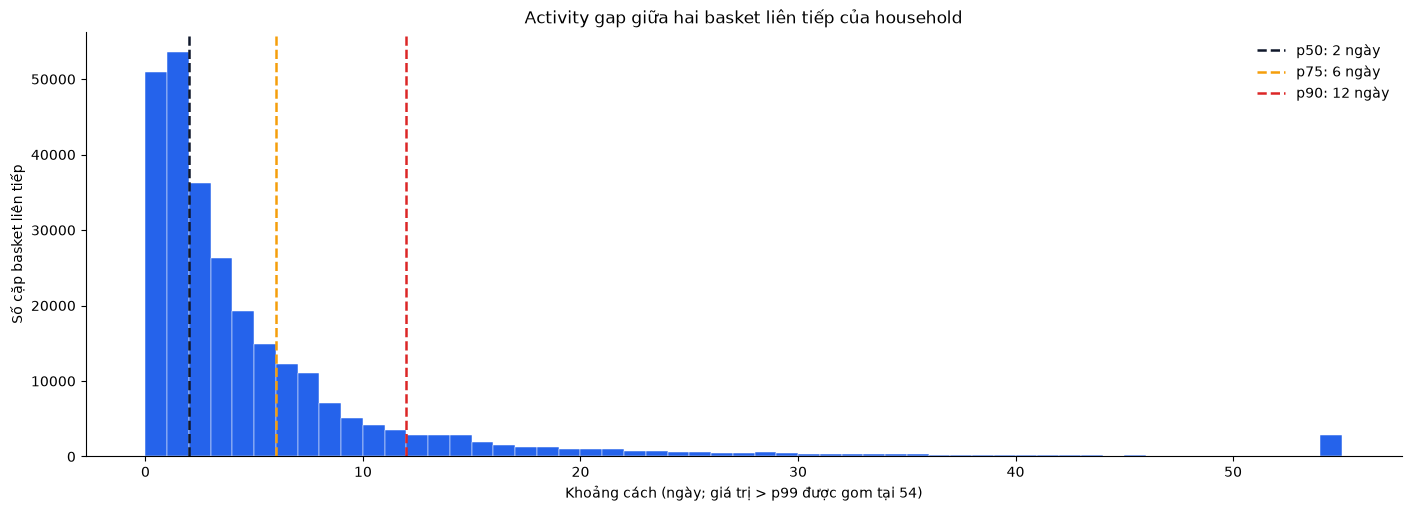

,gap_days
p50,2
p75,6
p90,12
p95,20
p99,54


In [71]:
basket_activity = (
    transaction_baskets
    .dropna(subset=["household_key", "BASKET_ID", "DAY"])
    .drop_duplicates(["household_key", "BASKET_ID"])
    .sort_values(["household_key", "DAY", "BASKET_ID"])
)
activity_gap_days = (
    basket_activity
    .groupby("household_key")["DAY"]
    .diff()
    .dropna()
    .astype("int64")
)

gap_percentiles = (
    activity_gap_days
    .quantile([0.50, 0.75, 0.90, 0.95, 0.99])
    .round()
    .astype("int64")
)
gap_percentiles.index = ["p50", "p75", "p90", "p95", "p99"]

gap_plot_limit = max(1, int(gap_percentiles.loc["p99"]))
activity_gap_figure, activity_gap_axis = plt.subplots(
    figsize=(14, 5), layout="constrained"
)
activity_gap_axis.hist(
    activity_gap_days.clip(upper=gap_plot_limit),
    bins=range(gap_plot_limit + 2),
    color="#2563EB",
    edgecolor="white",
    linewidth=0.35,
)
for percentile, color in (("p50", "#0F172A"), ("p75", "#F59E0B"), ("p90", "#DC2626")):
    gap_value = int(gap_percentiles.loc[percentile])
    activity_gap_axis.axvline(
        gap_value,
        color=color,
        linestyle="--",
        linewidth=1.8,
        label=f"{percentile}: {gap_value} ngày",
    )
activity_gap_axis.set(
    title="Activity gap giữa hai basket liên tiếp của household",
    xlabel=f"Khoảng cách (ngày; giá trị > p99 được gom tại {gap_plot_limit})",
    ylabel="Số cặp basket liên tiếp",
)
activity_gap_axis.spines[["top", "right"]].set_visible(False)
activity_gap_axis.legend(frameon=False)
plt.show()

gap_percentiles.rename("gap_days").to_frame()

## 13. Key integrity — cross-table

Kiểm tra coverage của foreign key từ transaction sang hai bảng dimension. Distinct-key coverage dùng các key khác null; row coverage giữ toàn bộ dòng transaction trong mẫu số, nên key null (nếu có) được tính là không match.

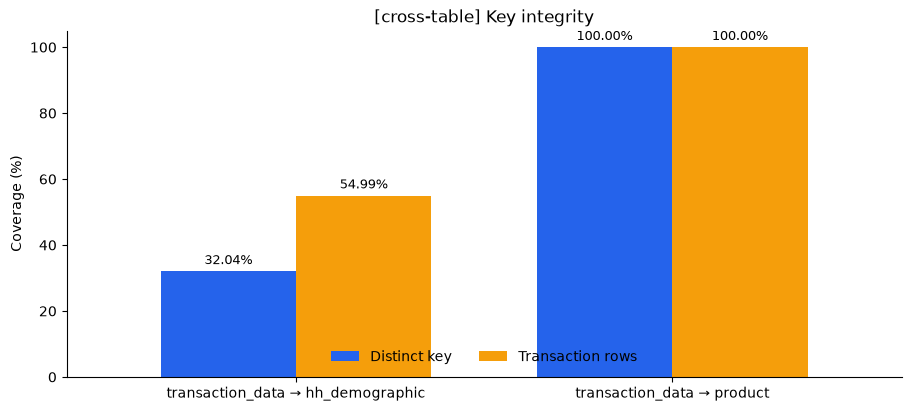

,relationship,key,distinct_keys_total,distinct_keys_matched,distinct_key_coverage_pct,source_rows,matched_rows,row_coverage_pct
0,transaction_data → hh_demographic,household_key,2500,801,32.04,2595732,1427303,54.986532
1,transaction_data → product,PRODUCT_ID,92339,92339,100.00,2595732,2595732,100.000000


In [72]:
transaction_keys = pd.read_csv(
    raw_dir / "transaction_data.csv",
    usecols=["household_key", "PRODUCT_ID"],
)
demographic_keys = pd.read_csv(
    raw_dir / "hh_demographic.csv", usecols=["household_key"]
)["household_key"].dropna().unique()
product_keys = pd.read_csv(
    raw_dir / "product.csv", usecols=["PRODUCT_ID"]
)["PRODUCT_ID"].dropna().unique()

def summarize_key_integrity(source, key, reference_keys, relationship):
    source_non_missing = source[key].dropna()
    source_distinct = source_non_missing.drop_duplicates()
    distinct_matches = source_distinct.isin(reference_keys)
    row_matches = source[key].notna() & source[key].isin(reference_keys)
    return {
        "relationship": relationship,
        "key": key,
        "distinct_keys_total": int(source_distinct.size),
        "distinct_keys_matched": int(distinct_matches.sum()),
        "distinct_key_coverage_pct": float(distinct_matches.mean() * 100),
        "source_rows": int(len(source)),
        "matched_rows": int(row_matches.sum()),
        "row_coverage_pct": float(row_matches.mean() * 100),
    }

key_integrity = pd.DataFrame([
    summarize_key_integrity(
        transaction_keys,
        "household_key",
        demographic_keys,
        "transaction_data → hh_demographic",
    ),
    summarize_key_integrity(
        transaction_keys,
        "PRODUCT_ID",
        product_keys,
        "transaction_data → product",
    ),
])

key_integrity_plot = key_integrity.set_index("relationship")[
    ["distinct_key_coverage_pct", "row_coverage_pct"]
].rename(columns={
    "distinct_key_coverage_pct": "Distinct key",
    "row_coverage_pct": "Transaction rows",
})
key_integrity_figure, key_integrity_axis = plt.subplots(
    figsize=(9, 4), layout="constrained"
)
key_integrity_plot.plot.bar(
    ax=key_integrity_axis, color=["#2563EB", "#F59E0B"], width=0.72
)
for container in key_integrity_axis.containers:
    key_integrity_axis.bar_label(
        container, labels=[f"{value:.2f}%" for value in container.datavalues],
        padding=3, fontsize=9,
    )
key_integrity_axis.set(
    title="[cross-table] Key integrity",
    xlabel="",
    ylabel="Coverage (%)",
    ylim=(0, 105),
)
key_integrity_axis.tick_params(axis="x", rotation=0)
key_integrity_axis.spines[["top", "right"]].set_visible(False)
key_integrity_axis.legend(frameon=False, ncol=2, loc="lower center")
plt.show()

key_integrity

## 14. Heatmap null — bảng × cột

Mỗi ô là phần trăm số hàng null của một cột trong bảng tương ứng, sử dụng `extended_null_mask`. Ô màu xám nghĩa là cột không tồn tại trong bảng. Dữ liệu được đọc theo chunk để giữ memory ổn định với `causal_data`.

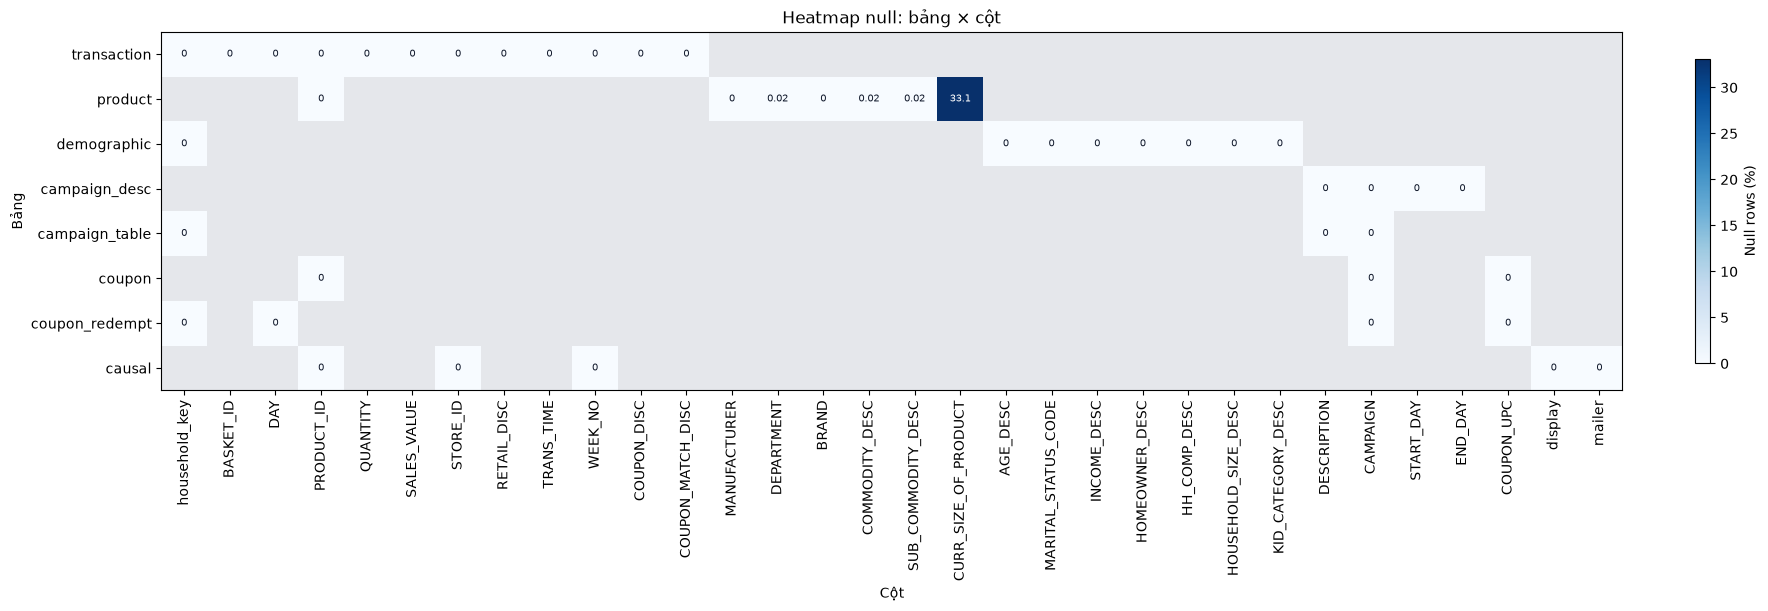

column,household_key,BASKET_ID,DAY,PRODUCT_ID,QUANTITY,SALES_VALUE,STORE_ID,RETAIL_DISC,TRANS_TIME,WEEK_NO,...,HH_COMP_DESC,HOUSEHOLD_SIZE_DESC,KID_CATEGORY_DESC,DESCRIPTION,CAMPAIGN,START_DAY,END_DAY,COUPON_UPC,display,mailer
table,,,,,,,,,,,,,,,,,,,,,
transaction,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
demographic,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
campaign_desc,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,0.0,0.0,0.0,0.0,NaN,NaN,NaN
campaign_table,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN
coupon,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,0.0,NaN,NaN,0.0,NaN,NaN
coupon_redempt,0.0,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,0.0,NaN,NaN,0.0,NaN,NaN
causal,NaN,NaN,NaN,0.0,NaN,NaN,0.0,NaN,NaN,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0


In [73]:
def build_null_heatmap(raw_dir, chunk_rows=250_000, null_tokens=NULL_TEXT_TOKENS):
    table_null_rates = {}
    for table_name, table_info in DUNNHUMBY_CATALOG.items():
        null_counts = None
        n_rows = 0
        for chunk in pd.read_csv(
            raw_dir / table_info.filename,
            chunksize=chunk_rows,
            keep_default_na=False,
        ):
            chunk_null_counts = pd.Series({
                column: int(extended_null_mask(
                    chunk[column], null_tokens=null_tokens
                ).sum())
                for column in chunk.columns
            })
            null_counts = (
                chunk_null_counts
                if null_counts is None
                else null_counts.add(chunk_null_counts, fill_value=0)
            )
            n_rows += len(chunk)
        table_null_rates[table_name] = (
            null_counts / n_rows * 100 if n_rows else pd.Series(dtype="float64")
        )
    return pd.DataFrame.from_dict(table_null_rates, orient="index").rename_axis(
        index="table", columns="column"
    )

null_heatmap = build_null_heatmap(raw_dir)
heatmap_values = null_heatmap.to_numpy(dtype="float64")
heatmap_max = max(1.0, float(null_heatmap.max(axis=None, skipna=True)))
heatmap_cmap = plt.colormaps["Blues"].copy()
heatmap_cmap.set_bad("#E5E7EB")

null_heatmap_figure, null_heatmap_axis = plt.subplots(
    figsize=(max(14, 0.55 * len(null_heatmap.columns)), 6),
    layout="constrained",
)
null_heatmap_image = null_heatmap_axis.imshow(
    heatmap_values,
    aspect="auto",
    cmap=heatmap_cmap,
    vmin=0,
    vmax=heatmap_max,
)
null_heatmap_axis.set_xticks(
    range(len(null_heatmap.columns)), null_heatmap.columns, rotation=90
)
null_heatmap_axis.set_yticks(
    range(len(null_heatmap.index)), null_heatmap.index
)
for row_index, table_name in enumerate(null_heatmap.index):
    for column_index, column_name in enumerate(null_heatmap.columns):
        value = null_heatmap.loc[table_name, column_name]
        if pd.notna(value):
            null_heatmap_axis.text(
                column_index,
                row_index,
                (
                    "0"
                    if value == 0
                    else f"{value:.2f}"
                    if value < 0.1
                    else f"{value:.1f}"
                ),
                ha="center",
                va="center",
                fontsize=7,
                color="white" if value > heatmap_max * 0.55 else "#0F172A",
            )
null_heatmap_axis.set(
    title="Heatmap null: bảng × cột",
    xlabel="Cột",
    ylabel="Bảng",
)
null_heatmap_figure.colorbar(
    null_heatmap_image, ax=null_heatmap_axis, label="Null rows (%)", shrink=0.85
)
plt.show()

null_heatmap